In [1]:
import pandas as pd
import numpy as np
from google.colab import drive

# ==========================================
# PERSIAPAN KONEKSI GOOGLE DRIVE
# ==========================================
# 1. Mount Google Drive ke Google Colab
print("Meminta akses ke Google Drive...")
drive.mount('/content/drive')

# 2. Tentukan Path File Dataset
file_path = '/content/drive/MyDrive/dataset/electric_vehicles_spec_2025_new.csv'
df = pd.read_csv(file_path)

Meminta akses ke Google Drive...
Mounted at /content/drive


In [2]:
# 1. Ukuran dataset
print("Ukuran dataset:", df.shape)
print("Jumlah data mobil:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

# 2. Lima baris pertama
display(df.head())

# 3. Informasi kolom dan tipe data
df.info()

# 4. Statistik deskriptif kolom numerik
display(df.describe().T)

Ukuran dataset: (478, 22)
Jumlah data mobil: 478
Jumlah kolom: 22


,brand,model,top_speed_kmh,battery_capacity_kWh,battery_type,number_of_cells,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,...,towing_capacity_kg,cargo_volume_l,seats,drivetrain,segment,length_mm,width_mm,height_mm,car_body_type,source_url
0,Abarth,500e Convertible,155,37.8,Lithium-ion,192.0,235.0,156,225,7.0,...,0.0,185,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1904/Abarth-500e-C...
1,Abarth,500e Hatchback,155,37.8,Lithium-ion,192.0,235.0,149,225,7.0,...,0.0,185,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1903/Abarth-500e-H...
2,Abarth,600e Scorpionissima,200,50.8,Lithium-ion,102.0,345.0,158,280,5.9,...,0.0,360,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.org/car/3057/Abarth-600e-S...
3,Abarth,600e Turismo,200,50.8,Lithium-ion,102.0,345.0,158,280,6.2,...,0.0,360,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.org/car/3056/Abarth-600e-T...
4,Aiways,U5,150,60.0,Lithium-ion,NaN,310.0,156,315,7.5,...,NaN,496,5,FWD,JC - Medium,4680,1865,1700,SUV,https://ev-database.org/car/1678/Aiways-U5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478 entries, 0 to 477
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   brand                      478 non-null    object 
 1   model                      477 non-null    object 
 2   top_speed_kmh              478 non-null    int64  
 3   battery_capacity_kWh       478 non-null    float64
 4   battery_type               478 non-null    object 
 5   number_of_cells            276 non-null    float64
 6   torque_nm                  471 non-null    float64
 7   efficiency_wh_per_km       478 non-null    int64  
 8   range_km                   478 non-null    int64  
 9   acceleration_0_100_s       478 non-null    float64
 10  fast_charging_power_kw_dc  477 non-null    float64
 11  fast_charge_port           477 non-null    object 
 12  towing_capacity_kg         452 non-null    float64
 13  cargo_volume_l             477 non-null    object 

,count,mean,std,min,25%,50%,75%,max
top_speed_kmh,478.0,185.487448,34.252773,125.0,160.0,180.00,201.00,325.0
battery_capacity_kWh,478.0,74.043724,20.331058,21.3,60.0,76.15,90.60,118.0
number_of_cells,276.0,485.293478,1210.819733,72.0,150.0,216.00,324.00,7920.0
torque_nm,471.0,498.012739,241.461128,113.0,305.0,430.00,679.00,1350.0
efficiency_wh_per_km,478.0,162.903766,34.317532,109.0,143.0,155.00,177.75,370.0
range_km,478.0,393.179916,103.287335,135.0,320.0,397.50,470.00,685.0
acceleration_0_100_s,478.0,6.882636,2.730696,2.2,4.8,6.60,8.20,19.1
fast_charging_power_kw_dc,477.0,125.008386,58.205012,29.0,80.0,113.00,150.00,281.0
towing_capacity_kg,452.0,1052.261062,737.851774,0.0,500.0,1000.00,1600.00,2500.0
seats,478.0,5.263598,1.003961,2.0,5.0,5.00,5.00,9.0


In [3]:
# 5. Pemeriksaan missing values
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

display(
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_count", ascending=False)
)

# 6. Pemeriksaan duplikasi
print("Jumlah baris duplikat:", df.duplicated().sum())

# 7. Periksa baris dengan model kosong
display(df[df["model"].isna()])

# 8. Periksa baris dengan daya pengisian cepat kosong
display(df[df["fast_charging_power_kw_dc"].isna()])


,missing_count,missing_percent
number_of_cells,202,42.26
towing_capacity_kg,26,5.44
torque_nm,7,1.46
model,1,0.21
fast_charging_power_kw_dc,1,0.21
fast_charge_port,1,0.21
cargo_volume_l,1,0.21


Jumlah baris duplikat: 0


,brand,model,top_speed_kmh,battery_capacity_kWh,battery_type,number_of_cells,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,...,towing_capacity_kg,cargo_volume_l,seats,drivetrain,segment,length_mm,width_mm,height_mm,car_body_type,source_url
477,firefly,NaN,150,41.2,Lithium-ion,112.0,200.0,125,250,8.1,...,0.0,404,5,RWD,B - Compact,4003,1885,1557,Hatchback,https://ev-database.org/car/3178/firefly-firefly


,brand,model,top_speed_kmh,battery_capacity_kWh,battery_type,number_of_cells,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,...,towing_capacity_kg,cargo_volume_l,seats,drivetrain,segment,length_mm,width_mm,height_mm,car_body_type,source_url
356,Renault,5 E-Tech 40kWh 95hp,130,40.0,Lithium-ion,93.0,215.0,129,255,12.0,...,500.0,326,5,FWD,B - Compact,3922,1808,1489,Hatchback,https://ev-database.org/car/2133/Renault-5-E-T...


In [4]:
# Enam kriteria yang digunakan dalam SAW
criteria = [
    "range_km",
    "top_speed_kmh",
    "battery_capacity_kWh",
    "fast_charging_power_kw_dc",
    "acceleration_0_100_s",
    "efficiency_wh_per_km",
]

# Periksa missing values dan statistik dasar enam kriteria
print("Missing values pada kriteria SAW:")
display(df[criteria].isna().sum().to_frame("missing_count"))

print("Statistik enam kriteria SAW:")
display(df[criteria].describe().T)

# Periksa nilai nol dan negatif
print("Jumlah nilai nol:")
display(df[criteria].eq(0).sum().to_frame("zero_count"))

print("Jumlah nilai negatif:")
display(df[criteria].lt(0).sum().to_frame("negative_count"))


Missing values pada kriteria SAW:


,missing_count
range_km,0
top_speed_kmh,0
battery_capacity_kWh,0
fast_charging_power_kw_dc,1
acceleration_0_100_s,0
efficiency_wh_per_km,0


Statistik enam kriteria SAW:


,count,mean,std,min,25%,50%,75%,max
range_km,478.0,393.179916,103.287335,135.0,320.0,397.50,470.00,685.0
top_speed_kmh,478.0,185.487448,34.252773,125.0,160.0,180.00,201.00,325.0
battery_capacity_kWh,478.0,74.043724,20.331058,21.3,60.0,76.15,90.60,118.0
fast_charging_power_kw_dc,477.0,125.008386,58.205012,29.0,80.0,113.00,150.00,281.0
acceleration_0_100_s,478.0,6.882636,2.730696,2.2,4.8,6.60,8.20,19.1
efficiency_wh_per_km,478.0,162.903766,34.317532,109.0,143.0,155.00,177.75,370.0


Jumlah nilai nol:


,zero_count
range_km,0
top_speed_kmh,0
battery_capacity_kWh,0
fast_charging_power_kw_dc,0
acceleration_0_100_s,0
efficiency_wh_per_km,0


Jumlah nilai negatif:


,negative_count
range_km,0
top_speed_kmh,0
battery_capacity_kWh,0
fast_charging_power_kw_dc,0
acceleration_0_100_s,0
efficiency_wh_per_km,0


In [5]:
# Periksa mobil dengan nilai fast charging yang kosong
missing_fast_charge = df[
    df["fast_charging_power_kw_dc"].isna()
]

display(
    missing_fast_charge[
        [
            "brand",
            "model",
            "battery_capacity_kWh",
            "range_km",
            "fast_charging_power_kw_dc",
            "source_url",
        ]
    ]
)


,brand,model,battery_capacity_kWh,range_km,fast_charging_power_kw_dc,source_url
356,Renault,5 E-Tech 40kWh 95hp,40.0,255,NaN,https://ev-database.org/car/2133/Renault-5-E-T...


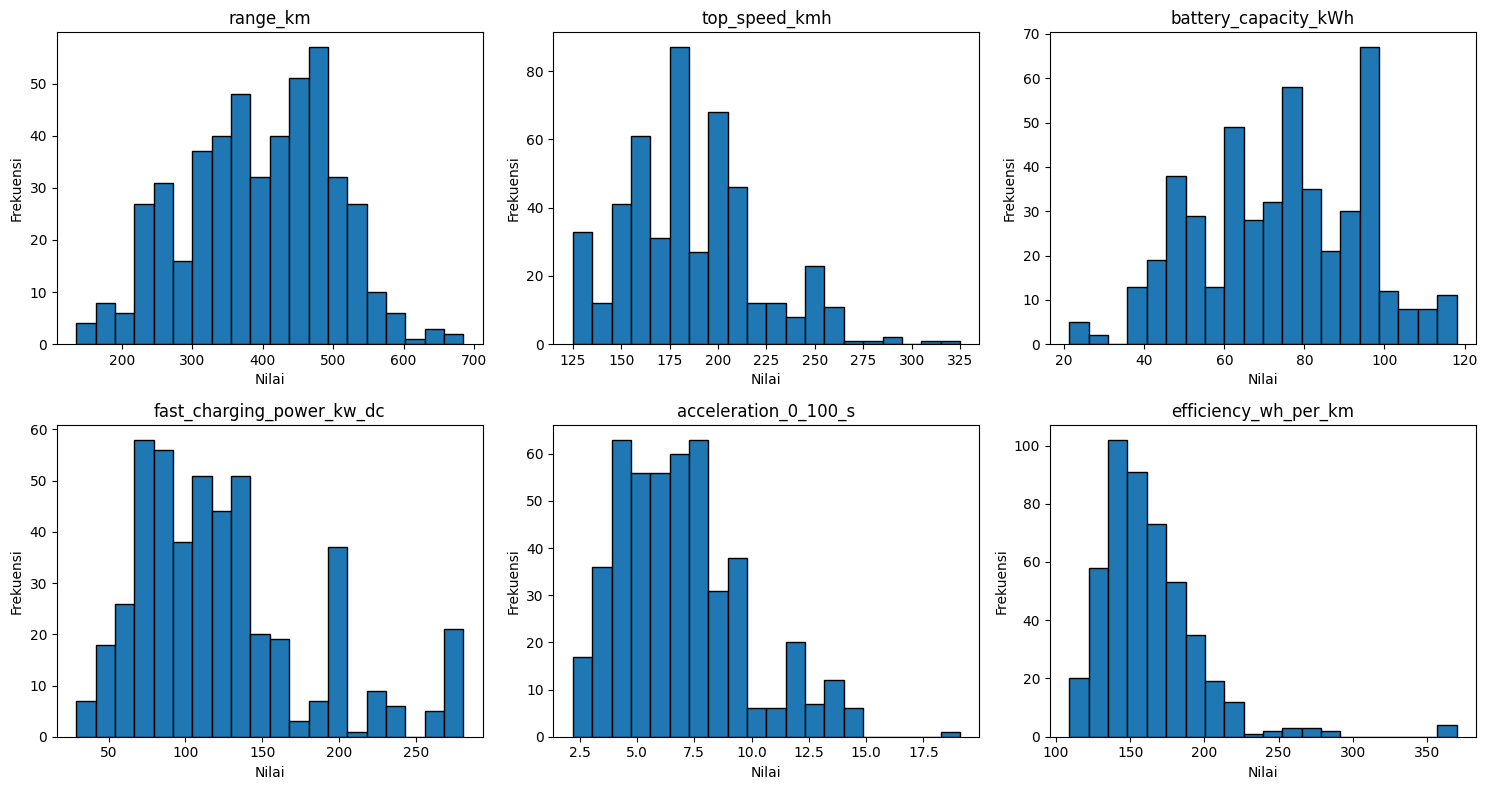

In [6]:
from matplotlib import pyplot as plt

criteria = [
    "range_km",
    "top_speed_kmh",
    "battery_capacity_kWh",
    "fast_charging_power_kw_dc",
    "acceleration_0_100_s",
    "efficiency_wh_per_km",
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), criteria):
    ax.hist(df[col].dropna(), bins=20, edgecolor="black")
    ax.set_title(col)
    ax.set_xlabel("Nilai")
    ax.set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()


In [7]:
# 1. Salin dataset agar data asli tetap tersimpan
df_preprocessed = df.copy()

# 2. Tangani model yang kosong
# Jika nama model tidak tersedia, gunakan brand sebagai label sementara
df_preprocessed["model"] = df_preprocessed["model"].fillna(
    df_preprocessed["brand"]
)

# 3. Isi nilai fast charging DC yang kosong dengan 0
df_preprocessed["fast_charging_power_kw_dc"] = (
    df_preprocessed["fast_charging_power_kw_dc"].fillna(0)
)

# 4. Tentukan enam kriteria SAW
criteria = [
    "range_km",
    "top_speed_kmh",
    "battery_capacity_kWh",
    "fast_charging_power_kw_dc",
    "acceleration_0_100_s",
    "efficiency_wh_per_km",
]

# 5. Ambil matriks keputusan
X = df_preprocessed[criteria].apply(
    pd.to_numeric, errors="raise"
)

# 6. Validasi sebelum normalisasi
print("Jumlah alternatif:", len(df_preprocessed))
print("Nilai kosong per kriteria:")
display(X.isna().sum().to_frame("missing_count"))

assert X.notna().all().all(), "Masih ada nilai kosong!"
assert (X >= 0).all().all(), "Ada nilai negatif!"

print("Preprocessing selesai.")


Jumlah alternatif: 478
Nilai kosong per kriteria:


,missing_count
range_km,0
top_speed_kmh,0
battery_capacity_kWh,0
fast_charging_power_kw_dc,0
acceleration_0_100_s,0
efficiency_wh_per_km,0


Preprocessing selesai.


In [8]:

# Jenis masing-masing kriteria
benefit_criteria = [
    "range_km",
    "top_speed_kmh",
    "battery_capacity_kWh",
    "fast_charging_power_kw_dc",
]

cost_criteria = [
    "acceleration_0_100_s",
    "efficiency_wh_per_km",
]

# Buat matriks normalisasi
R = pd.DataFrame(index=X.index)

# Normalisasi benefit
for col in benefit_criteria:
    max_value = X[col].max()
    R[col] = X[col] / max_value

# Normalisasi cost
for col in cost_criteria:
    min_value = X[col].min()
    R[col] = min_value / X[col]

# Pertahankan urutan kriteria yang telah ditetapkan
R = R[criteria]

print("Matriks normalisasi SAW:")
display(R.head())

print("Statistik hasil normalisasi:")
display(R.describe().T)


Matriks normalisasi SAW:


,range_km,top_speed_kmh,battery_capacity_kWh,fast_charging_power_kw_dc,acceleration_0_100_s,efficiency_wh_per_km
0,0.328467,0.476923,0.320339,0.238434,0.314286,0.698718
1,0.328467,0.476923,0.320339,0.238434,0.314286,0.731544
2,0.408759,0.615385,0.430508,0.281139,0.372881,0.689873
3,0.408759,0.615385,0.430508,0.281139,0.354839,0.689873
4,0.459854,0.461538,0.508475,0.277580,0.293333,0.698718


Statistik hasil normalisasi:


,count,mean,std,min,25%,50%,75%,max
range_km,478.0,0.573985,0.150784,0.197080,0.467153,0.580292,0.686131,1.0
top_speed_kmh,478.0,0.570731,0.105393,0.384615,0.492308,0.553846,0.618462,1.0
battery_capacity_kWh,478.0,0.627489,0.172297,0.180508,0.508475,0.645339,0.767797,1.0
fast_charging_power_kw_dc,478.0,0.443939,0.207916,0.000000,0.284698,0.400356,0.533808,1.0
acceleration_0_100_s,478.0,0.373581,0.155010,0.115183,0.268293,0.333333,0.458333,1.0
efficiency_wh_per_km,478.0,0.692412,0.117976,0.294595,0.613224,0.703226,0.762238,1.0


In [9]:
# Bobot baseline: semua kriteria memiliki bobot sama
weights_baseline = {
    col: 1 / len(criteria)
    for col in criteria
}

# Hitung skor preferensi SAW
scores_baseline = R.mul(
    pd.Series(weights_baseline)
).sum(axis=1)

# Susun hasil peringkat
baseline_results = df_preprocessed[
    ["brand", "model"]
].copy()

baseline_results["score_saw"] = scores_baseline
baseline_results["rank"] = (
    baseline_results["score_saw"]
    .rank(method="min", ascending=False)
    .astype(int)
)

baseline_results = baseline_results.sort_values(
    ["score_saw", "brand", "model"],
    ascending=[False, True, True]
).reset_index(drop=True)

print("Top 10 rekomendasi SAW - Baseline:")
display(baseline_results.head(10))


Top 10 rekomendasi SAW - Baseline:


,brand,model,score_saw,rank
0,Porsche,Taycan Turbo GT Weissach,0.843247,1
1,Porsche,Taycan Turbo GT,0.826114,2
2,Porsche,Taycan Turbo S,0.821927,3
3,Lucid,Air Grand Touring,0.816850,4
4,Porsche,Taycan Turbo S Sport Turismo,0.811926,5
5,Porsche,Taycan Turbo,0.807385,6
6,Audi,e-tron GT RS performance,0.806098,7
7,Porsche,Taycan Turbo Sport Turismo,0.794411,8
8,Porsche,Taycan Turbo S Cross Turismo,0.793180,9
9,Audi,e-tron GT RS,0.789299,10


In [10]:

# Definisi bobot setiap skenario
scenarios = {
    "Baseline": {
        "range_km": 1/6,
        "top_speed_kmh": 1/6,
        "battery_capacity_kWh": 1/6,
        "fast_charging_power_kw_dc": 1/6,
        "acceleration_0_100_s": 1/6,
        "efficiency_wh_per_km": 1/6,
    },
    "S1_Range": {
        "range_km": 0.60,
        "top_speed_kmh": 0.08,
        "battery_capacity_kWh": 0.08,
        "fast_charging_power_kw_dc": 0.08,
        "acceleration_0_100_s": 0.08,
        "efficiency_wh_per_km": 0.08,
    },
    "S2_Performance": {
        "range_km": 0.05,
        "top_speed_kmh": 0.40,
        "battery_capacity_kWh": 0.05,
        "fast_charging_power_kw_dc": 0.05,
        "acceleration_0_100_s": 0.40,
        "efficiency_wh_per_km": 0.05,
    },
    "S3_Efficiency_Charging": {
        "range_km": 0.05,
        "top_speed_kmh": 0.05,
        "battery_capacity_kWh": 0.05,
        "fast_charging_power_kw_dc": 0.40,
        "acceleration_0_100_s": 0.05,
        "efficiency_wh_per_km": 0.40,
    },
}

# Validasi bobot
for scenario_name, weights in scenarios.items():
    assert abs(sum(weights.values()) - 1.0) < 1e-9, (
        f"Jumlah bobot {scenario_name} tidak sama dengan 1"
    )

# Hitung skor dan peringkat seluruh alternatif
scenario_results = {}

for scenario_name, weights in scenarios.items():
    weight_series = pd.Series(weights)

    scores = R.mul(weight_series).sum(axis=1)

    result = df_preprocessed[["brand", "model"]].copy()
    result["score_saw"] = scores
    result["rank"] = (
        result["score_saw"]
        .rank(method="min", ascending=False)
        .astype(int)
    )

    result = result.sort_values(
        ["score_saw", "brand", "model"],
        ascending=[False, True, True]
    ).reset_index(drop=True)

    scenario_results[scenario_name] = result

# Tampilkan Top 10 untuk setiap skenario
for scenario_name, result in scenario_results.items():
    print(f"\nTop 10 - {scenario_name}")
    display(result.head(10))



Top 10 - Baseline


,brand,model,score_saw,rank
0,Porsche,Taycan Turbo GT Weissach,0.843247,1
1,Porsche,Taycan Turbo GT,0.826114,2
2,Porsche,Taycan Turbo S,0.821927,3
3,Lucid,Air Grand Touring,0.816850,4
4,Porsche,Taycan Turbo S Sport Turismo,0.811926,5
5,Porsche,Taycan Turbo,0.807385,6
6,Audi,e-tron GT RS performance,0.806098,7
7,Porsche,Taycan Turbo Sport Turismo,0.794411,8
8,Porsche,Taycan Turbo S Cross Turismo,0.793180,9
9,Audi,e-tron GT RS,0.789299,10



Top 10 - S1_Range


,brand,model,score_saw,rank
0,Lucid,Air Grand Touring,0.896906,1
1,Mercedes-Benz,EQS 450+,0.856036,2
2,Mercedes-Benz,EQS 450 4MATIC,0.830288,3
3,Mercedes-Benz,EQS 580 4MATIC,0.826272,4
4,Mercedes-Benz,EQS 500 4MATIC,0.822191,5
5,Audi,A6 Sportback e-tron performance,0.801714,6
6,Porsche,Taycan 4S Plus,0.799025,7
7,Tesla,Model S Plaid,0.795902,8
8,Porsche,Taycan Plus,0.794599,9
9,Lucid,Air Touring,0.793901,10



Top 10 - S2_Performance


,brand,model,score_saw,rank
0,Porsche,Taycan Turbo GT Weissach,0.931436,1
1,Porsche,Taycan Turbo GT,0.894925,2
2,Tesla,Model S Plaid,0.870220,3
3,Maserati,GranTurismo Folgore,0.860310,4
4,Porsche,Taycan Turbo S,0.847411,5
5,Porsche,Taycan Turbo S Sport Turismo,0.844411,6
6,Audi,e-tron GT RS performance,0.819060,7
7,Porsche,Taycan Turbo S Cross Turismo,0.815185,8
8,Porsche,Taycan Turbo,0.807401,9
9,Porsche,Taycan Turbo Sport Turismo,0.803508,10



Top 10 - S3_Efficiency_Charging


,brand,model,score_saw,rank
0,Mercedes-Benz,CLA 250+,0.817880,1
1,Porsche,Taycan Turbo S,0.815831,2
2,Porsche,Taycan Turbo GT Weissach,0.814919,3
3,Mercedes-Benz,CLA 350 4MATIC,0.811471,4
4,Porsche,Taycan Turbo,0.811468,5
5,Porsche,Taycan Turbo GT,0.805171,6
6,Audi,e-tron GT S,0.804051,7
7,Audi,e-tron GT quattro,0.803698,8
8,Porsche,Taycan Turbo S Sport Turismo,0.802048,9
9,Audi,e-tron GT RS performance,0.801445,10


In [11]:

from scipy.stats import spearmanr
from itertools import combinations

# Pastikan identitas alternatif unik
for name, result in scenario_results.items():
    duplicated = result.duplicated(
        subset=["brand", "model"]
    ).sum()

    print(f"{name}: {duplicated} identitas duplikat")

# Gabungkan peringkat setiap skenario berdasarkan identitas mobil
rank_tables = []

for name, result in scenario_results.items():
    temp = result[["brand", "model", "rank"]].copy()
    temp = temp.rename(columns={"rank": name})
    rank_tables.append(temp)

rank_comparison = rank_tables[0]

for table in rank_tables[1:]:
    rank_comparison = rank_comparison.merge(
        table,
        on=["brand", "model"],
        how="inner",
        validate="one_to_one"
    )

print("Jumlah mobil yang dibandingkan:", len(rank_comparison))

# Hitung korelasi Spearman untuk setiap pasangan skenario
correlation_results = []

scenario_names = list(scenario_results.keys())

for scenario_a, scenario_b in combinations(scenario_names, 2):
    rho, p_value = spearmanr(
        rank_comparison[scenario_a],
        rank_comparison[scenario_b]
    )

    correlation_results.append({
        "scenario_1": scenario_a,
        "scenario_2": scenario_b,
        "spearman_rho": rho,
        "p_value": p_value
    })

spearman_results = pd.DataFrame(correlation_results)

Baseline: 0 identitas duplikat
S1_Range: 0 identitas duplikat
S2_Performance: 0 identitas duplikat
S3_Efficiency_Charging: 0 identitas duplikat
Jumlah mobil yang dibandingkan: 478


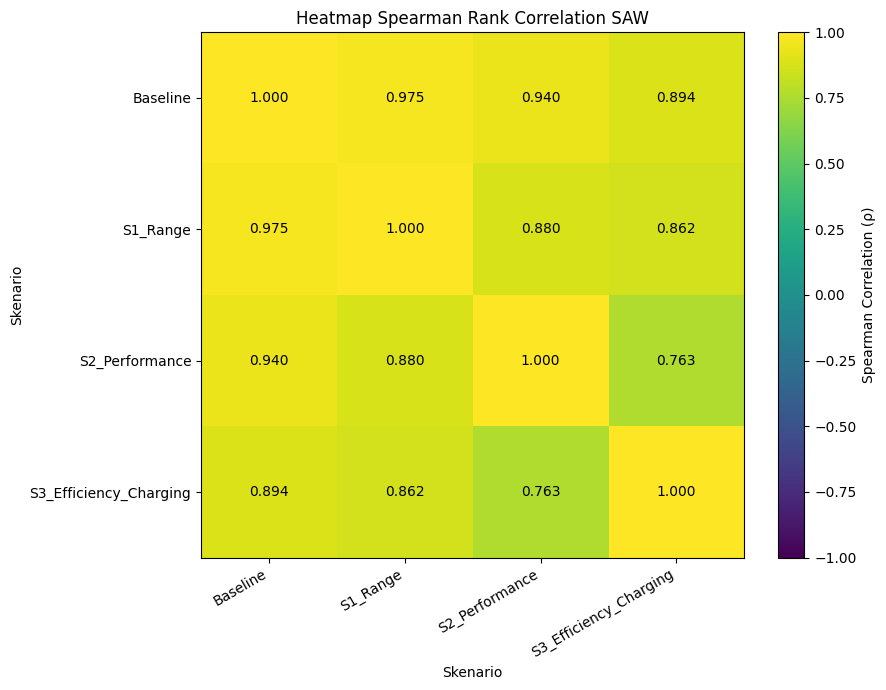

In [12]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Buat matriks korelasi dari hasil pengujian Spearman sebelumnya
scenarios = list(scenario_results.keys())

correlation_matrix = pd.DataFrame(
    np.eye(len(scenarios)),
    index=scenarios,
    columns=scenarios,
)

for _, row in spearman_results.iterrows():
    scenario_1 = row["scenario_1"]
    scenario_2 = row["scenario_2"]
    rho = row["spearman_rho"]

    correlation_matrix.loc[scenario_1, scenario_2] = rho
    correlation_matrix.loc[scenario_2, scenario_1] = rho

# Visualisasi heatmap
fig, ax = plt.subplots(figsize=(9, 7))

heatmap = ax.imshow(
    correlation_matrix.values,
    vmin=-1,
    vmax=1,
    aspect="auto",
)

ax.set_xticks(range(len(scenarios)))
ax.set_yticks(range(len(scenarios)))
ax.set_xticklabels(scenarios, rotation=30, ha="right")
ax.set_yticklabels(scenarios)

# Tampilkan nilai korelasi di setiap sel
for i in range(len(scenarios)):
    for j in range(len(scenarios)):
        ax.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.3f}",
            ha="center",
            va="center",
        )

ax.set_title("Heatmap Spearman Rank Correlation SAW")
ax.set_xlabel("Skenario")
ax.set_ylabel("Skenario")

fig.colorbar(
    heatmap,
    ax=ax,
    label="Spearman Correlation (ρ)",
)

plt.tight_layout()
plt.show()


In [13]:

overlap_results = []

for scenario_a, scenario_b in combinations(scenario_names, 2):
    top_a = set(
        zip(
            scenario_results[scenario_a].head(10)["brand"],
            scenario_results[scenario_a].head(10)["model"]
        )
    )

    top_b = set(
        zip(
            scenario_results[scenario_b].head(10)["brand"],
            scenario_results[scenario_b].head(10)["model"]
        )
    )

    overlap_results.append({
        "scenario_1": scenario_a,
        "scenario_2": scenario_b,
        "jumlah_mobil_sama": len(top_a & top_b),
        "mobil_yang_sama": sorted(top_a & top_b)
    })

overlap_df = pd.DataFrame(overlap_results)

display(
    overlap_df[
        ["scenario_1", "scenario_2", "jumlah_mobil_sama"]
    ]
)


,scenario_1,scenario_2,jumlah_mobil_sama
0,Baseline,S1_Range,1
1,Baseline,S2_Performance,8
2,Baseline,S3_Efficiency_Charging,6
3,S1_Range,S2_Performance,1
4,S1_Range,S3_Efficiency_Charging,0
5,S2_Performance,S3_Efficiency_Charging,6


In [14]:
import numpy as np
import pandas as pd

def calculate_ws_coefficient(r1, r2):
    r1 = np.array(r1, dtype=float)
    r2 = np.array(r2, dtype=float)
    N = len(r1)

    if len(r2) != N:
        raise ValueError("Panjang r1 dan r2 harus sama.")

    # Pembilang: absolut selisih posisi
    numerator = np.abs(r1 - r2)

    # Penyebut: jarak maksimum yang mungkin untuk posisi tersebut
    denominator = np.maximum(np.abs(1.0 - r1), np.abs(N - r1))

    # Hindari pembagian dengan nol jika N = 1
    denominator = np.where(denominator == 0, 1.0, denominator)

    # Bobot eksponensial berdasarkan peringkat acuan
    weights = 2.0 ** (-r1)

    # Kalkulasi nilai WS
    ws_score = 1.0 - np.sum(weights * (numerator / denominator))
    return float(ws_score)

In [16]:
# =========================================================
# 1. PERSIAPAN DATAFRAME PERINGKAT
# =========================================================
# Gabungkan hasil peringkat dari semua skenario ke dalam satu DataFrame
rank_df = pd.DataFrame({'model': df_preprocessed['model']})

for scenario_name, result in scenario_results.items():
    # Mapping peringkat kembali ke urutan indeks asli dataframe
    sorted_rank = result.set_index('model')['rank']
    rank_df[scenario_name] = rank_df['model'].map(sorted_rank)

# =========================================================
# 2. PERHITUNGAN MATRIKS WS COEFFICIENT
# =========================================================
scenario_names = list(scenarios)
ws_matrix = pd.DataFrame(index=scenario_names, columns=scenario_names, dtype=float)

for s1 in scenario_names:
    for s2 in scenario_names:
        ws_val = calculate_ws_coefficient(rank_df[s1], rank_df[s2])
        ws_matrix.loc[s1, s2] = ws_val

print("=== Matriks WS Coefficient Antar Skenario ===")
display(ws_matrix.round(4))

# =========================================================
# 3. PERBANDINGAN KHUSUS TERHADAP BASELINE
# =========================================================
ws_vs_baseline = ws_matrix['Baseline'].to_frame('WS_vs_Baseline')
print("\n=== Tingkat Kesamaan Skenario Terhadap Baseline ===")
display(ws_vs_baseline.round(4))

=== Matriks WS Coefficient Antar Skenario ===


,Baseline,S1_Range,S2_Performance,S3_Efficiency_Charging
Baseline,1.0000,0.9546,0.9982,0.9918
S1_Range,0.9533,1.0000,0.8756,0.8632
S2_Performance,0.9949,0.9449,1.0000,0.9666
S3_Efficiency_Charging,0.9541,0.9599,0.8492,1.0000



=== Tingkat Kesamaan Skenario Terhadap Baseline ===


,WS_vs_Baseline
Baseline,1.0000
S1_Range,0.9533
S2_Performance,0.9949
S3_Efficiency_Charging,0.9541


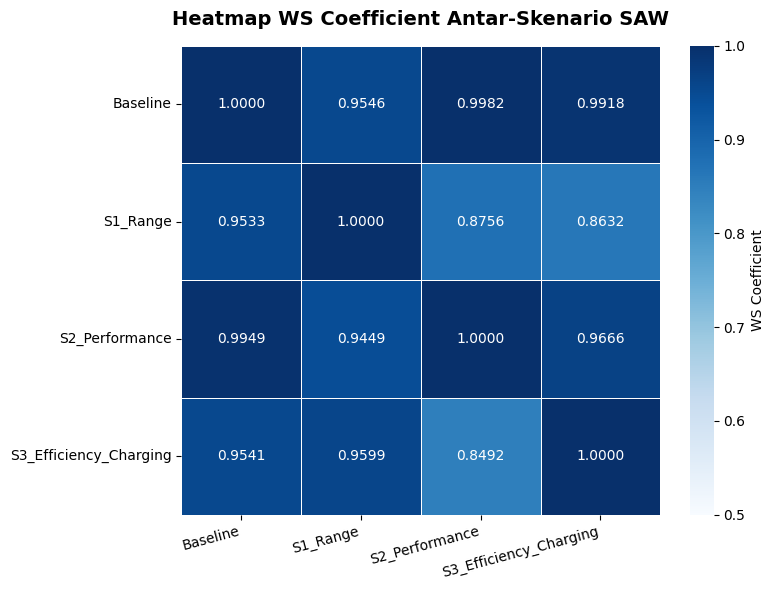

In [17]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# =========================================================
# 1. MEMBUAT VISUALISASI HEATMAP
# =========================================================
plt.figure(figsize=(8, 6))

# Membuat heatmap dengan Seaborn
sns.heatmap(
    ws_matrix,
    annot=True,  # Menampilkan angka di dalam sel
    fmt=".4f",  # Format angka desimal (4 digit di belakang koma)
    cmap="Blues",  # Skala warna (semakin gelap, nilai WS semakin tinggi/mirip)
    vmin=0.5,  # Nilai minimum skala warna
    vmax=1.0,  # Nilai maksimum skala warna
    linewidths=0.5,  # Garis pemisah antar sel
    linecolor="white",  # Warna garis pemisah
    cbar_kws={"label": "WS Coefficient"},
)

# Kustomisasi judul dan label sumbu
plt.title(
    "Heatmap WS Coefficient Antar-Skenario SAW",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xticks(rotation=15, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

# Simpan atau tampilkan plot
plt.savefig("ws_coefficient_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()